Dataset Shape: (569, 31)
Missing Values: 0

Accuracy Score: 92.98%

Classification Report:
              precision    recall  f1-score   support

   malignant       0.90      0.90      0.90        42
      benign       0.94      0.94      0.94        72

    accuracy                           0.93       114
   macro avg       0.92      0.92      0.92       114
weighted avg       0.93      0.93      0.93       114

Confusion Matrix:
[[38  4]
 [ 4 68]]


<ipython-input-4-ab46f921f560>:55: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig("decision_tree_structure.png", dpi=300, bbox_inches="tight")
<ipython-input-4-ab46f921f560>:55: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig("decision_tree_structure.png", dpi=300, bbox_inches="tight")


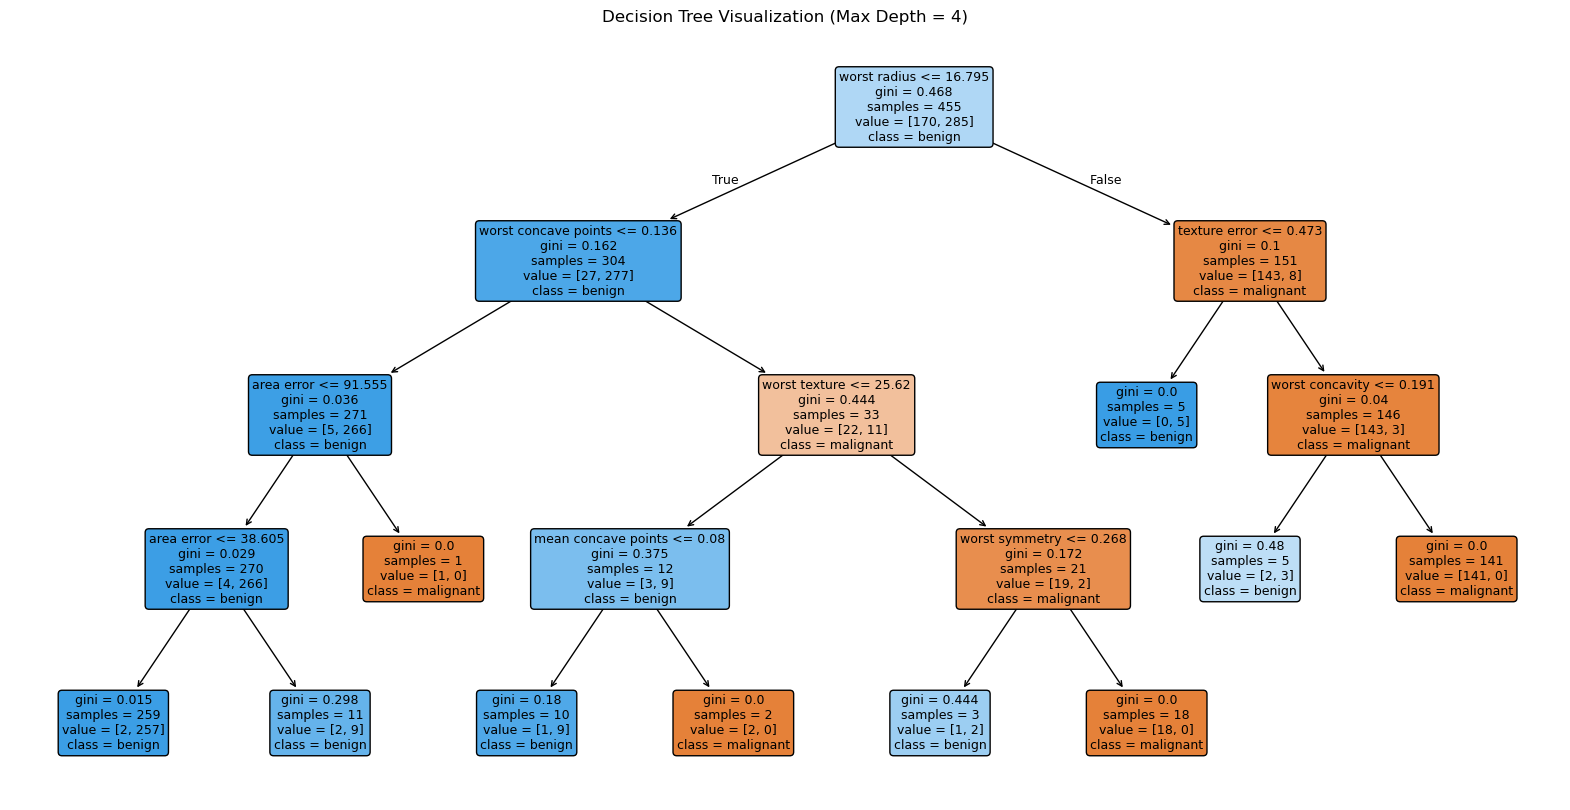

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

# 1. Load Built-in Dataset (Avoids network/HTTP OSError in browser-based Jupyter)
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df["Outcome"] = data.target

# Optional: Save dataset locally as CSV so you can upload it to your GitHub repository
df.to_csv("breast_cancer_dataset.csv", index=False)

# 2. Data Verification (Check for missing values)
print(f"Dataset Shape: {df.shape}")
print(f"Missing Values: {df.isnull().sum().sum()}\n")

# 3. Train-Test Split (80% Train, 20% Test, Stratified)
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 4. Train Decision Tree Model with Pre-Pruning
dt_classifier = DecisionTreeClassifier(
    criterion="gini", max_depth=4, min_samples_split=10, random_state=42
)
dt_classifier.fit(X_train, y_train)

# 5. Model Evaluation
y_pred = dt_classifier.predict(X_test)

print(f"Accuracy Score: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=data.target_names))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# 6. Decision Tree Visualization
plt.figure(figsize=(20, 10))
plot_tree(
    dt_classifier,
    feature_names=X.columns,
    class_names=list(data.target_names),
    filled=True,
    rounded=True,
    fontsize=9,
)
plt.title("Decision Tree Visualization (Max Depth = 4)")
plt.savefig("decision_tree_structure.png", dpi=300, bbox_inches="tight")
plt.show()